In [1]:
%load_ext autoreload
%autoreload 2

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helpers import *
import os

from helpers import *
from Code.costs import *
from Code.implementations import *

from Code.Logistic_SGD import stochastic_logistic_regression_reg, cross_validation_logreg

In [3]:
data_path = "data/dataset"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

## Preprocessing

In [4]:
nan_ratio = np.isnan(x_train).mean(axis=0)
mask = nan_ratio < 0.8
x_tr = x_train[:, mask]
x_te = x_test[:, mask]   

med = np.nanmedian(x_tr, axis=0)
x_tr = np.where(np.isnan(x_tr), med, x_tr)
x_te = np.where(np.isnan(x_te), med, x_te)

mean = x_tr.mean(axis=0)
std = x_tr.std(axis=0)
std[std == 0] = 1.0
x_tr = (x_tr - mean) / std
x_te = (x_te - mean) / std

y_tr = y_train

y_tr[y_tr==-1] = 0 # mapping for logistic regression


## Training model

In [5]:
w_zero = np.zeros(x_tr.shape[1])

w, loss = stochastic_logistic_regression_reg(y_train, x_tr, w_zero,batch_size=500, max_iters=200, gamma=0.02, lambda_=0)

In [6]:
from Code.helpers import build_k_indices
from plots import cross_validation_visualization


def cross_validation_logreg_demo(y, x, k_fold, gammas, max_iters, batch_size, lambda_):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """


    print("Unique y values:", np.unique(y))
    print("x mean, std min/max:", np.mean(x), np.min(np.std(x, axis=0)), np.max(np.std(x, axis=0)))

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            print("Computing gamma=", gamma, 'fold: ',k, "#######################")
            loss_tr, loss_te = cross_validation_logreg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
            diff = abs(loss_tr - loss_te)
            print(f"Train: {loss_tr:.6f} | Test: {loss_te:.6f} | Absolute Diff: {diff:.6e}")
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

Unique y values: [0 1]
x mean, std min/max: -2.0441420275197611e-13 0.0 1.0000000000000002
Computing gamma= 0.0001 ----------------------------
Computing gamma= 0.0001 fold:  0 #######################
Train: 0.688495 | Test: 0.688477 | Absolute Diff: 1.814325e-05
Computing gamma= 0.0001 fold:  1 #######################
Train: 0.688474 | Test: 0.688473 | Absolute Diff: 1.034118e-06
Computing gamma= 0.0001 fold:  2 #######################
Train: 0.688449 | Test: 0.688450 | Absolute Diff: 9.713880e-07
Computing gamma= 0.0001 fold:  3 #######################
Train: 0.688384 | Test: 0.688365 | Absolute Diff: 1.903363e-05
Computing gamma= 0.0001 fold:  4 #######################
Train: 0.688428 | Test: 0.688460 | Absolute Diff: 3.167295e-05
Computing gamma= 0.0001 fold:  5 #######################
Train: 0.688466 | Test: 0.688513 | Absolute Diff: 4.683572e-05
Computing gamma= 0.0001 fold:  6 #######################
Train: 0.688478 | Test: 0.688388 | Absolute Diff: 8.990828e-05
Computing gamma=

/Users/maguettediouf/Documents/Machine Learning/ML_project1/Code/costs.py:22: RuntimeWarning: divide by zero encountered in log
  loss = y.T.dot(np.log(pred)) + (1 - y).T.dot(np.log(1 - pred))


Train: inf | Test: 0.245667 | Absolute Diff: inf
Computing gamma= 1.0 fold:  6 #######################
Train: 0.256769 | Test: 0.252371 | Absolute Diff: 4.397792e-03
Computing gamma= 1.0 fold:  7 #######################
Train: 0.247577 | Test: 0.244617 | Absolute Diff: 2.959796e-03
Computing gamma= 1.0 fold:  8 #######################
Train: 0.250585 | Test: 0.250379 | Absolute Diff: 2.056948e-04
Computing gamma= 1.0 fold:  9 #######################
Train: inf | Test: 0.259082 | Absolute Diff: inf
For SGD, the choice of gamma which leads to the best test mse is 0.35938 with a test mse of 0.234


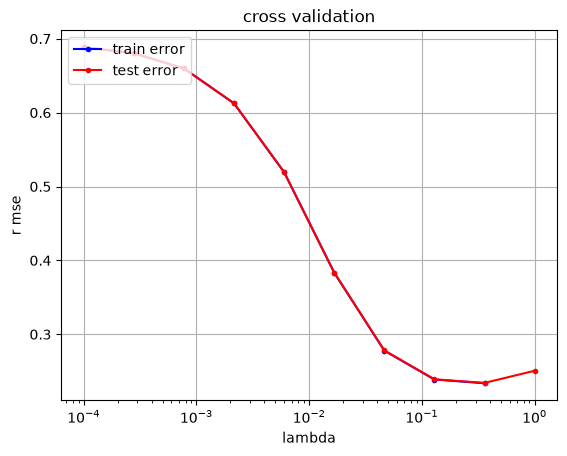

In [8]:
k_fold = 10
gammas = np.logspace(-4, 0, 10)
max_iters = 50
batch_size = 250

best_gamma, best_mse = cross_validation_logreg_demo(y_train, x_tr, k_fold=k_fold,batch_size=250, max_iters=200, gammas=gammas, lambda_=0)

In [10]:
## PRED + SUBMISSION FILE
x_test_path = os.path.join(data_path, 'x_test.csv')
df_x_test = pd.read_csv(x_test_path)

pred = (sigmoid(x_te @ w) >= 0.5).astype(int)
pred[pred == 0] = -1
create_csv_submission(df_x_test["Id"], pred, "submission_log_reg.csv")

# Final model training

In [8]:
def best_gamma_lambda_selection(y,x, k_fold, gammas, max_iters, batch_size, lambdas, seed=1):
    """cross validation over regularisation parameter lambda and degree.

    Args:
        degrees: shape = (d,), where d is the number of degrees to test
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_degree : integer, value of the best degree
        best_lambda : scalar, value of the best lambda
        best_rmse : value of the rmse for the couple (best_degree, best_lambda)

    >>> best_degree_selection(np.arange(2,11), 4, np.logspace(-4, 0, 30))
    (7, 0.004520353656360241, 0.2895728056656946)
    """

    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)

    test_loss_grid = np.zeros((len(gammas), len(lambdas)))
    train_loss_grid = np.zeros((len(gammas), len(lambdas)))

    # vary degree
    for i, gamma in enumerate(gammas):
        print('################ Computing gamma: ', gamma, '###################')
        # cross validation
        rmse_te = []
        for j, lambda_ in enumerate(lambdas):
            print(f'Computing gamma: {gamma} & lambda: {lambda_}-------------')
            te_losses, tr_losses = [], []
            for k in range(k_fold):
                print(f'Computing gamma: {gamma} & lambda: {lambda_} FOLD {k} ||||||||||||')
                loss_tr, loss_te = cross_validation_logreg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
                tr_losses.append(loss_tr)
                te_losses.append(loss_te)

            test_loss_grid[i, j] = np.mean(te_losses)
            train_loss_grid[i, j] = np.mean(tr_losses)

    best_i, best_j = np.unravel_index(np.argmin(test_loss_grid), test_loss_grid.shape)
    best_gamma = gammas[best_i]
    best_lambda = lambdas[best_j]
    best_loss = test_loss_grid[best_i, best_j]

    return float(best_gamma), float(best_lambda), float(best_loss), test_loss_grid, train_loss_grid

################ Computing gamma:  0.0001 ###################
Computing gamma: 0.0001 & lambda: 0.0001-------------
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 0 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 1 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 2 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 3 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 4 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 5 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 6 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 7 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 8 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0001 FOLD 9 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0002782559402207126-------------
Computing gamma: 0.0001 & lambda: 0.0002782559402207126 FOLD 0 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.0002782559402207126 FOLD 1 ||||||||||||
Computing gamma: 0.0001 & lambda: 0.00027825594022071

/home/robin/EPFL/MA3/machineLearning/ML_project1/Code/costs.py:22: RuntimeWarning: divide by zero encountered in log
  loss = y.T.dot(np.log(pred)) + (1 - y).T.dot(np.log(1 - pred))


Computing gamma: 1.0 & lambda: 0.0002782559402207126 FOLD 5 ||||||||||||
Computing gamma: 1.0 & lambda: 0.0002782559402207126 FOLD 6 ||||||||||||
Computing gamma: 1.0 & lambda: 0.0002782559402207126 FOLD 7 ||||||||||||
Computing gamma: 1.0 & lambda: 0.0002782559402207126 FOLD 8 ||||||||||||
Computing gamma: 1.0 & lambda: 0.0002782559402207126 FOLD 9 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127-------------
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 0 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 1 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 2 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 3 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 4 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 5 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 6 ||||||||||||
Computing gamma: 1.0 & lambda: 0.000774263682681127 FOLD 7 |||||||

NameError: name 'best_loss' is not defined

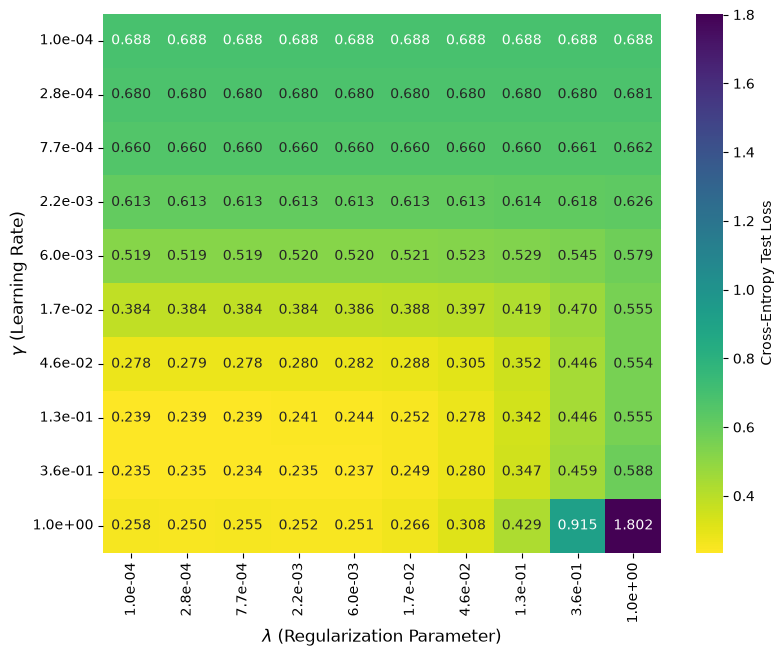

In [ ]:
import seaborn as sns

k_fold = 10
gammas = np.logspace(-4, 0, 10)
lambdas = np.logspace(-4, 0, 10)
max_iters = 200
batch_size = 250

# will take some time to run :)
best_gamma, best_lambda, best_rmse, test_loss_grid, train_loss_grid = best_gamma_lambda_selection(y_train, x_tr, k_fold=k_fold,batch_size=batch_size, max_iters=max_iters, gammas=gammas, lambdas=lambdas)

gamma_labels = [f"{g:.1e}" for g in gammas]
lambda_labels = [f"{l:.1e}" for l in lambdas]

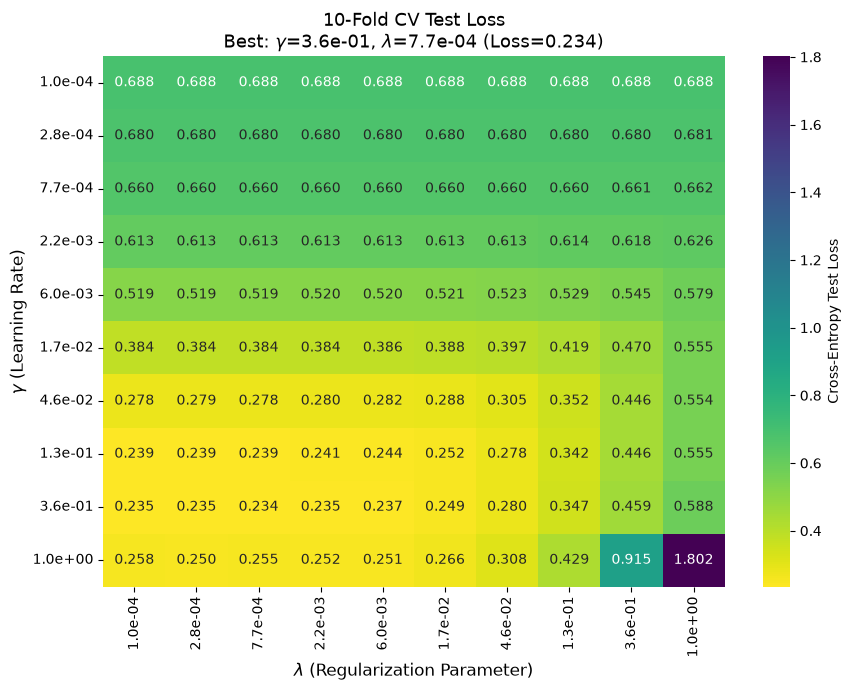

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(
    test_loss_grid,
    xticklabels=lambda_labels,
    yticklabels=gamma_labels,
    annot=True,          # Displays loss values in cells
    fmt=".3f",          # 3 decimal places
    cmap="viridis_r",    # Darker/richer color represents lower loss
    cbar_kws={'label': 'Cross-Entropy Test Loss'}
)

plt.xlabel(r"$\lambda$ (Regularization Parameter)", fontsize=12)
plt.ylabel(r"$\gamma$ (Learning Rate)", fontsize=12)
plt.title(f"10-Fold CV Test Loss\nBest: $\\gamma$={best_gamma:.1e}, $\\lambda$={best_lambda:.1e} (Loss={best_rmse:.3f})", fontsize=13)
plt.tight_layout()
plt.show()